<a href="https://colab.research.google.com/github/Samarbal/Deep-Learning-/blob/main/DL_DNN_Architecture_and_Hyperparameter_Tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## DNN Architecture and Hyperparameter Tuning

Samar Balousha

2320222601

Deep learning assignemt 1

In [ ]:
# import the required labraries
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.21.0


### **Task 1: Activation Functions Exploration**

In [ ]:
# input vales to explore how the activation functions works
x = tf.constant([-10.0, -2.0, 0.0, 2.0, 10.0, 30, 25])

sigmoid_output = tf.keras.activations.sigmoid(x)
relu_output = tf.keras.activations.relu(x)

print(f"Input: {x.numpy()}")
print(f"Sigmoid: {sigmoid_output.numpy()}")
print(f"ReLU: {relu_output.numpy()}")

Input: [-10.  -2.   0.   2.  10.  30.  25.]
Sigmoid: [4.5397868e-05 1.1920292e-01 5.0000000e-01 8.8079703e-01 9.9995458e-01
 1.0000000e+00 1.0000000e+00]
ReLU: [ 0.  0.  0.  2. 10. 30. 25.]


* Sigmoid: Maps input values into the continuous range of $(0, 1)$.
* ReLU: Returns $0$ for zero or negative input values, and outputs positive inputs as they are ($x$).

### **Task 2: Building a Neural Network**

In [ ]:
# Building a Deep Neural Network with 3 Hidden Layers and 5 Output Classes

model = keras.Sequential([
    # 1st hidden layer: 64 units, input shape of 20 features, ReLU activation
    keras.layers.Dense(units=64, activation='relu', input_shape=(20,)),

    # 2nd hidden layer: 32 units, ReLU activation
    keras.layers.Dense(units=32, activation='relu'),

    # 3rd hidden layer: 16 units, ReLU activation (Newly added layer)
    keras.layers.Dense(units=16, activation='relu'),

    # Output layer: 5 units for 5 classes, Softmax activation for probability distribution
    keras.layers.Dense(units=5, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,037 (15.77 KB)

 Trainable params: 4,037 (15.77 KB)

 Non-trainable params: 0 (0.00 B)

analysis for the output
* input layer = (20 inputs *64 units ) + 64 biases =1344  params
* 2nd layer = (64 inputs * 32 units)+ 32 biases= 2080 params
* 3rd layer = (32 inputs * 16 units) + 16 biases = 528 params
* output layer = (16 inputs * 5 units )+ 5 biases = 85 params

- trainable parameters:  4037 params


### **Task 3 :Training and Hyperparameter Tuning**

In [ ]:
#  Model Compilation and Training
model.compile( optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# generate random data for 20 features and 5 categories
np.random.seed(42)
x_train = np.random.random((1000, 20))
y_train = np.random.randint(5, size=(1000,))   # 5=>categories (0,1,2,3,4,)

# train the model
history = model.fit(
    x_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.6700 - loss: 0.8860 - val_accuracy: 0.2550 - val_loss: 2.2661
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6875 - loss: 0.8633 - val_accuracy: 0.2200 - val_loss: 2.2975
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6900 - loss: 0.8567 - val_accuracy: 0.2400 - val_loss: 2.2884
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7025 - loss: 0.8421 - val_accuracy: 0.2350 - val_loss: 2.3248
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7075 - loss: 0.8401 - val_accuracy: 0.2400 - val_loss: 2.3377
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7025 - loss: 0.8350 - val_accuracy: 0.2300 - val_loss: 2.3332
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7138 - loss: 0.8295 - val_accuracy: 0.2300 - val_loss: 2.3461
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7050 - loss: 0.8274 - val_accuracy: 0.2250 - v

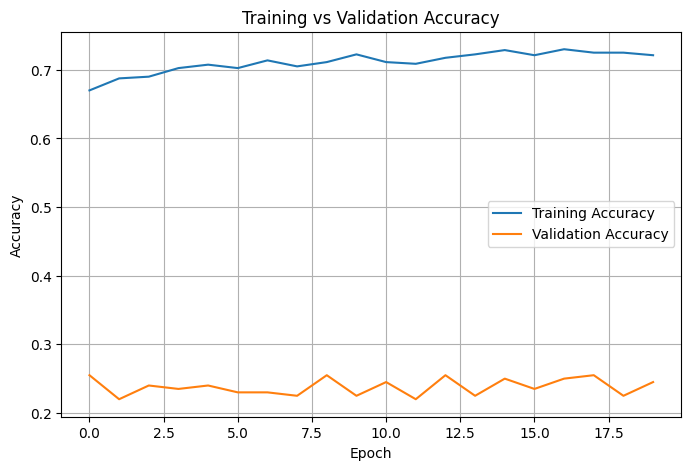

In [ ]:
#Plotting Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

The training accuracy started high (~67%) because model.fit() was executed multiple times (3 times ) without resetting the model, allowing it to continue training on previously learned weights.

However, while training accuracy reached over 72%, validation accuracy remained weak (~23%).

This indicates **overfitting**; since the dataset is purely random, the model is merely memorizing the training samples instead of learning actual patterns, leaving validation accuracy near random guessing ($1/5 = 20\%$).